In [6]:
from google.colab import files

uploaded = files.upload()

Saving Pro-Kabaddi-League-Analysis-main.zip to Pro-Kabaddi-League-Analysis-main.zip


In [27]:
import zipfile
from pathlib import Path

zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("/content/pkl_project")

print("Project extracted successfully!")

Project extracted successfully!


In [26]:
from pathlib import Path

base = Path("/content/pkl_project")

data_dirs = list(base.rglob("pkl_matches_s1_s10.csv"))

if not data_dirs:
    raise FileNotFoundError(
        "Could not find pkl_matches_s1_s10.csv. "
        "Check that you uploaded the correct repository ZIP."
    )

DATA = data_dirs[0].parent

print("Data directory:", DATA)
print("Files:", [p.name for p in DATA.iterdir()])

Data directory: /content/pkl_project/Pro-Kabaddi-League-Analysis-main/data
Files: ['pkl_player_match_points.csv', 'AllSeasons_AllTeams_DefenderSuccessRate.csv', 'PKL_AggregatedTeamStats.csv', 'ALL_Defensive_Skills_Merged.csv', 'pkl_matches_s1_s10.csv', 'ALL_Raider_Skills_Merged.csv', 'AllSeasons_AllTeams_RaiderSuccessRate.csv', 'all_seasons_player_stats_rounded.csv']


In [9]:
%pip install -q pandas numpy matplotlib seaborn scipy

**Import libraries and load the data**

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

matches = pd.read_csv(DATA / "pkl_matches_s1_s10.csv")
players = pd.read_csv(DATA / "pkl_player_match_points.csv")
teams = pd.read_csv(DATA / "PKL_AggregatedTeamStats.csv")
player_stats = pd.read_csv(
    DATA / "all_seasons_player_stats_rounded.csv"
)

print("Matches:", matches.shape)
print("Player-match records:", players.shape)
print("Team statistics:", teams.shape)
print("Player statistics:", player_stats.shape)

Matches: (1064, 13)
Player-match records: (13737, 8)
Team statistics: (116, 56)
Player statistics: (1636, 43)


**Inspect the datasets**

In [11]:
display(matches.head())
display(players.head())
display(teams.head())

print("\nMatch columns:")
print(matches.columns.tolist())

print("\nMissing values in match data:")
print(matches.isnull().sum())

print("\nMissing values in player data:")
print(players.isnull().sum())

print("\nAvailable seasons:")
print(sorted(matches["season"].dropna().unique()))

,season,game_id,match_name,match_date,stage,venue,team_1,score_1,team_2,score_2,winner,margin,result_text
0,1,1,Match 1,2014-07-26,League,"DOME,NSCI,SVP STADIUM,MUMBAI",U Mumba,45,Jaipur Pink Panthers,31,U Mumba,14,U Mumba beat Jaipur Pink Panthers (45 - 31)
1,1,2,Match 2,2014-07-26,League,"DOME,NSCI,SVP STADIUM,MUMBAI",Dabang Delhi,28,Bengaluru Bulls,47,Bengaluru Bulls,19,Bengaluru Bulls beat Dabang Delhi (47 - 28)
2,1,3,Match 3,2014-07-27,League,"DOME,NSCI,SVP STADIUM,MUMBAI",Bengaluru Bulls,40,Puneri Paltan,37,Bengaluru Bulls,3,Bengaluru Bulls beat Puneri Paltan (40 - 37)
3,1,4,Match 4,2014-07-27,League,"DOME,NSCI,SVP STADIUM,MUMBAI",U Mumba,36,Bengal Warriors,25,U Mumba,11,U Mumba beat Bengal Warriors (36 - 25)
4,1,5,Match 5,2014-07-28,League,"DOME,NSCI,SVP STADIUM,MUMBAI",Puneri Paltan,31,Dabang Delhi,35,Dabang Delhi,4,Dabang Delhi beat Puneri Paltan (35 - 31)


,season,game_id,match_date,team,player_id,player_name,player_role,points
0,1,1,2014-07-26,U Mumba,29,Anup Kumar,NaN,14
1,1,1,2014-07-26,U Mumba,146,Surender Nada,Defender,9
2,1,1,2014-07-26,U Mumba,105,Shabeer Bappu,NaN,8
3,1,1,2014-07-26,U Mumba,94,Rishank Devadiga,NaN,5
4,1,1,2014-07-26,U Mumba,54,Jeeva Kumar,NaN,3


,season,team_id,team_name,matches_played,team-average-raid-points_rank,team-avg-points-scored_rank,team-all-outs-conceded_rank,team-successful-tackle-percent_rank,team-super-raid_rank,team-raid_rank,...,team-super-tackles_per-match,team-total-touch-points-ext_per-match,team-total-bonus--points-ext_per-match,team-raid-points_per-match,team-successful-raids_per-match,team-total-points-conceded_per-match,team-tackle-points_per-match,team-total-points_per-match,team-all-outs-inflicted_per-match,team-successful-tackles_per-match
0,1,1,Bengaluru Bulls,16,8,6,7,NaN,7,NaN,...,0.625,0.0,0.0,18.188,14.375,29.938,10.188,31.125,2.500,9.563
1,1,2,Dabang Delhi K.C.,14,4,4,3,NaN,8,NaN,...,0.714,0.0,0.0,20.357,17.643,33.643,9.571,32.571,2.571,8.857
2,1,3,Jaipur Pink Panthers,16,3,1,6,NaN,5,NaN,...,0.750,0.0,0.0,21.500,17.563,28.625,10.625,36.188,3.625,9.875
3,1,4,Bengal Warriors,14,5,7,2,NaN,4,NaN,...,1.143,0.0,0.0,20.214,15.714,36.786,8.714,30.714,1.571,7.571
4,1,5,U Mumba,16,2,3,4,NaN,1,NaN,...,0.750,0.0,0.0,21.688,17.625,31.188,9.813,34.375,2.625,9.063



Match columns:
['season', 'game_id', 'match_name', 'match_date', 'stage', 'venue', 'team_1', 'score_1', 'team_2', 'score_2', 'winner', 'margin', 'result_text']

Missing values in match data:
season          0
game_id         0
match_name      0
match_date      0
stage           0
venue          16
team_1          0
score_1         0
team_2          0
score_2         0
winner          0
margin          0
result_text    27
dtype: int64

Missing values in player data:
season            0
game_id           0
match_date        0
team              0
player_id         0
player_name       0
player_role    4771
points            0
dtype: int64

Available seasons:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


**Clean and validate the data**

In [12]:
matches = matches.drop_duplicates().copy()
players = players.drop_duplicates().copy()

TEAM_ALIASES = {
    "Dabang Delhi": "Dabang Delhi K.C.",
    "Dabang Delhi KC": "Dabang Delhi K.C.",
    "U.P. Yoddha": "U.P. Yoddhas",
    "UP Yoddha": "U.P. Yoddhas",
}

def clean_team_name(value):
    if pd.isna(value):
        return value
    value = str(value).strip()
    return TEAM_ALIASES.get(value, value)

for col in ["team_1", "team_2", "winner"]:
    matches[col] = matches[col].map(clean_team_name)

players["team"] = players["team"].map(clean_team_name)

matches["match_date"] = pd.to_datetime(
    matches["match_date"], errors="coerce"
)

for col in ["score_1", "score_2", "margin", "season"]:
    matches[col] = pd.to_numeric(matches[col], errors="coerce")

matches["total_points"] = matches["score_1"] + matches["score_2"]
matches["calculated_margin"] = (
    matches["score_1"] - matches["score_2"]
).abs()

matches["calculated_winner"] = np.select(
    [
        matches["score_1"] > matches["score_2"],
        matches["score_2"] > matches["score_1"]
    ],
    [
        matches["team_1"],
        matches["team_2"]
    ],
    default="Tie"
)

print("Remaining duplicate match rows:", matches.duplicated().sum())
print(
    "Winner mismatches:",
    (matches["winner"] != matches["calculated_winner"]).sum()
)
print(
    "Margin mismatches:",
    (matches["margin"] != matches["calculated_margin"]).sum()
)

Remaining duplicate match rows: 0
Winner mismatches: 0
Margin mismatches: 0


**inspect duplicate matches using their business identifiers**

In [13]:
match_key = [
    "season", "match_date",
    "team_1", "score_1", "team_2", "score_2"
]

print(
    "Duplicate match identifiers:",
    matches.duplicated(subset=match_key).sum()
)

Duplicate match identifiers: 0


**Create a match-level summary**

In [14]:
season_summary = (
    matches.groupby("season")
    .agg(
        matches_played=("game_id", "count"),
        average_total_points=("total_points", "mean"),
        average_margin=("margin", "mean"),
        tied_matches=("calculated_winner",
                      lambda x: (x == "Tie").sum()),
        close_matches=("margin", lambda x: (x <= 3).sum())
    )
    .reset_index()
)

season_summary["tie_percentage"] = (
    100 * season_summary["tied_matches"]
    / season_summary["matches_played"]
)

season_summary["close_match_percentage"] = (
    100 * season_summary["close_matches"]
    / season_summary["matches_played"]
)

display(season_summary.round(2))

,season,matches_played,average_total_points,average_margin,tied_matches,close_matches,tie_percentage,close_match_percentage
0,1,60,68.20,8.33,6,22,10.00,36.67
1,2,60,60.37,8.17,4,18,6.67,30.00
2,3,60,60.07,9.43,4,14,6.67,23.33
3,4,60,59.08,6.52,5,23,8.33,38.33
4,5,138,63.98,7.27,16,54,11.59,39.13
5,6,138,66.49,7.76,14,38,10.14,27.54
6,7,137,67.60,7.93,13,51,9.49,37.23
7,8,137,68.28,7.74,16,51,11.68,37.23
8,9,137,72.04,8.32,12,45,8.76,32.85
9,10,137,71.99,9.20,11,46,8.03,33.58


**Visualize scoring trends**

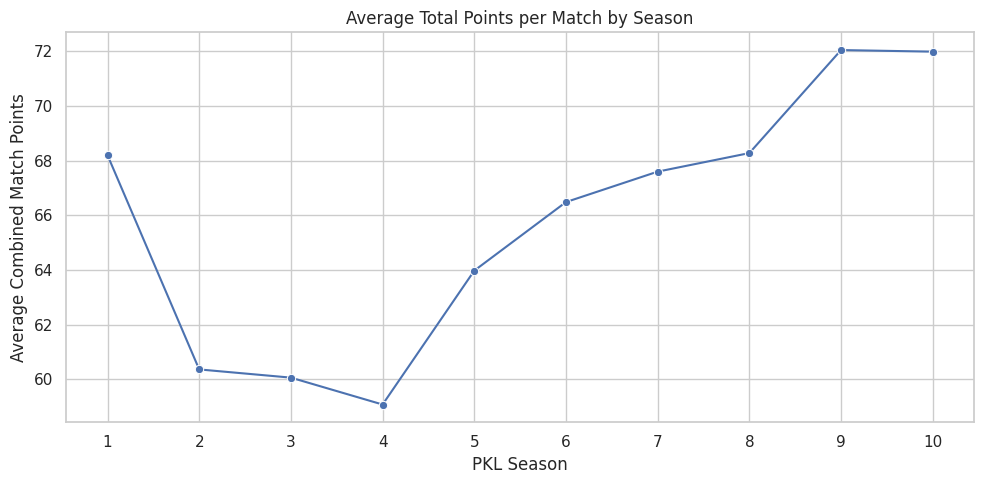

In [15]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=season_summary,
    x="season",
    y="average_total_points",
    marker="o"
)

plt.title("Average Total Points per Match by Season")
plt.xlabel("PKL Season")
plt.ylabel("Average Combined Match Points")
plt.xticks(season_summary["season"])
plt.tight_layout()
plt.show()

**Create a second chart for match margins**

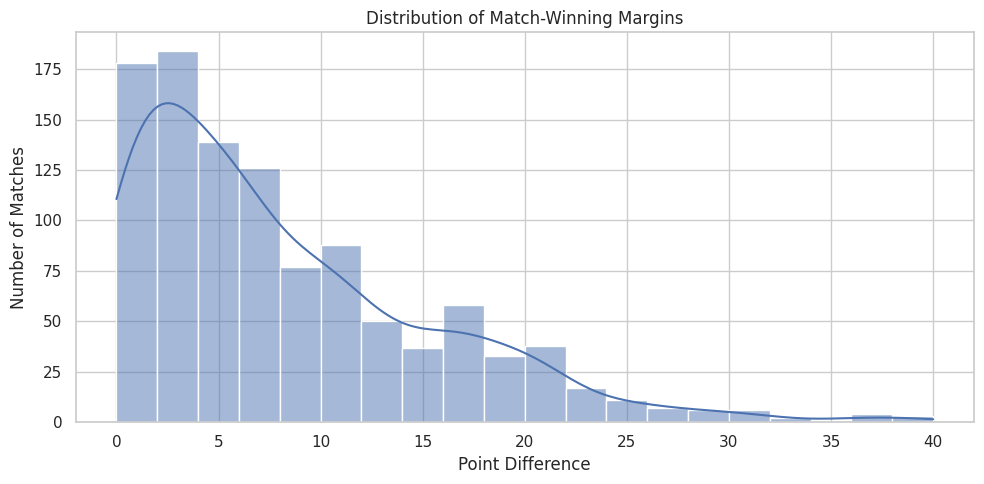

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=matches,
    x="margin",
    bins=20,
    kde=True
)

plt.title("Distribution of Match-Winning Margins")
plt.xlabel("Point Difference")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()

**Calculate team standings and win percentages**

In [17]:
team_1 = matches[
    ["season", "game_id", "team_1", "score_1", "score_2",
     "calculated_winner"]
].copy()

team_1.columns = [
    "season", "game_id", "team", "points_for",
    "points_against", "winner"
]

team_1["result"] = np.where(
    team_1["winner"] == "Tie", "T",
    np.where(team_1["team"] == team_1["winner"], "W", "L")
)

team_2 = matches[
    ["season", "game_id", "team_2", "score_2", "score_1",
     "calculated_winner"]
].copy()

team_2.columns = [
    "season", "game_id", "team", "points_for",
    "points_against", "winner"
]

team_2["result"] = np.where(
    team_2["winner"] == "Tie", "T",
    np.where(team_2["team"] == team_2["winner"], "W", "L")
)

team_matches = pd.concat(
    [team_1, team_2], ignore_index=True
)

standings = (
    team_matches.groupby(["season", "team"])
    .agg(
        played=("result", "size"),
        wins=("result", lambda x: (x == "W").sum()),
        losses=("result", lambda x: (x == "L").sum()),
        ties=("result", lambda x: (x == "T").sum()),
        points_for=("points_for", "sum"),
        points_against=("points_against", "sum")
    )
    .reset_index()
)

standings["win_percentage"] = (
    100 * standings["wins"] / standings["played"]
)

standings["point_difference"] = (
    standings["points_for"] - standings["points_against"]
)

display(
    standings.sort_values(
        ["season", "win_percentage", "point_difference"],
        ascending=[True, False, False]
    ).round(2)
)

,season,team,played,wins,losses,ties,points_for,points_against,win_percentage,point_difference
3,1,Jaipur Pink Panthers,16,12,3,1,609,478,75.00,131
7,1,U Mumba,16,9,4,3,571,519,56.25,52
1,1,Bengaluru Bulls,16,8,7,1,524,499,50.00,25
4,1,Patna Pirates,16,8,6,2,524,519,50.00,5
6,1,Telugu Titans,14,6,5,3,516,490,42.86,26
...,...,...,...,...,...,...,...,...,...,...
92,10,Bengal Warriors,22,9,11,2,820,863,40.91,-43
93,10,Bengaluru Bulls,22,8,12,2,734,801,36.36,-67
102,10,U Mumba,22,6,13,3,796,875,27.27,-79
103,10,U.P. Yoddhas,22,4,17,1,743,859,18.18,-116


**Calculate all-time team performance**

In [18]:
all_time = (
    team_matches.groupby("team")
    .agg(
        played=("result", "size"),
        wins=("result", lambda x: (x == "W").sum()),
        losses=("result", lambda x: (x == "L").sum()),
        ties=("result", lambda x: (x == "T").sum())
    )
    .reset_index()
)

all_time["win_percentage"] = (
    100 * all_time["wins"] / all_time["played"]
)

all_time = all_time.sort_values(
    "win_percentage", ascending=False
)

display(all_time.round(2))

,team,played,wins,losses,ties,win_percentage
10,U Mumba,197,106,78,13,53.81
3,Gujarat Giants,139,73,53,13,52.52
6,Patna Pirates,204,107,77,20,52.45
5,Jaipur Pink Panthers,195,97,81,17,49.74
4,Haryana Steelers,137,67,57,13,48.91
7,Puneri Paltan,199,96,86,17,48.24
1,Bengaluru Bulls,200,94,93,13,47.00
0,Bengal Warriors,195,86,87,22,44.10
2,Dabang Delhi K.C.,196,84,93,19,42.86
11,U.P. Yoddhas,140,58,66,16,41.43


**Plot the results**

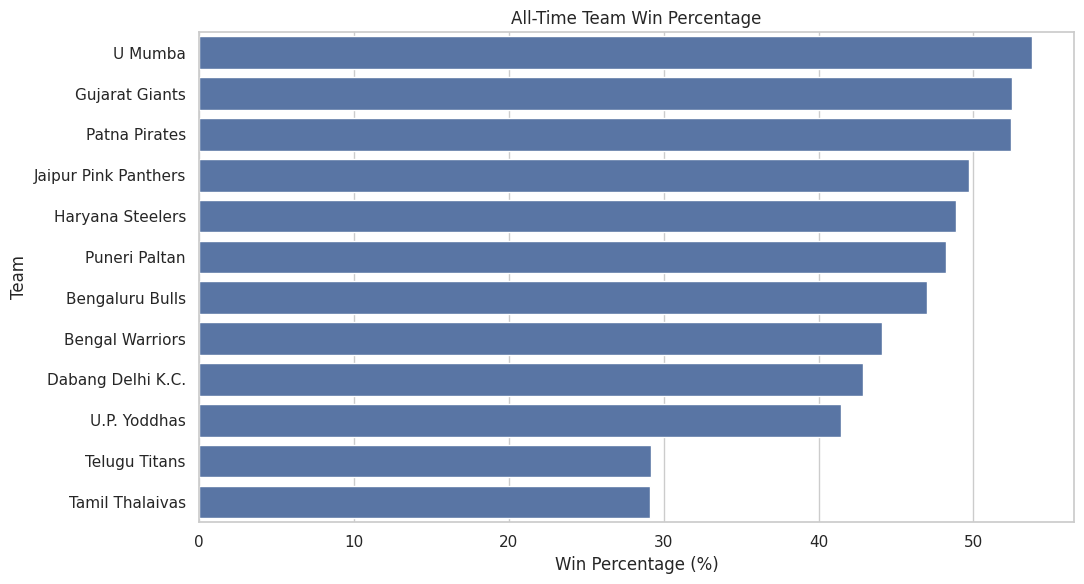

In [19]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=all_time,
    x="win_percentage",
    y="team"
)

plt.title("All-Time Team Win Percentage")
plt.xlabel("Win Percentage (%)")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

**Plot the top 10**

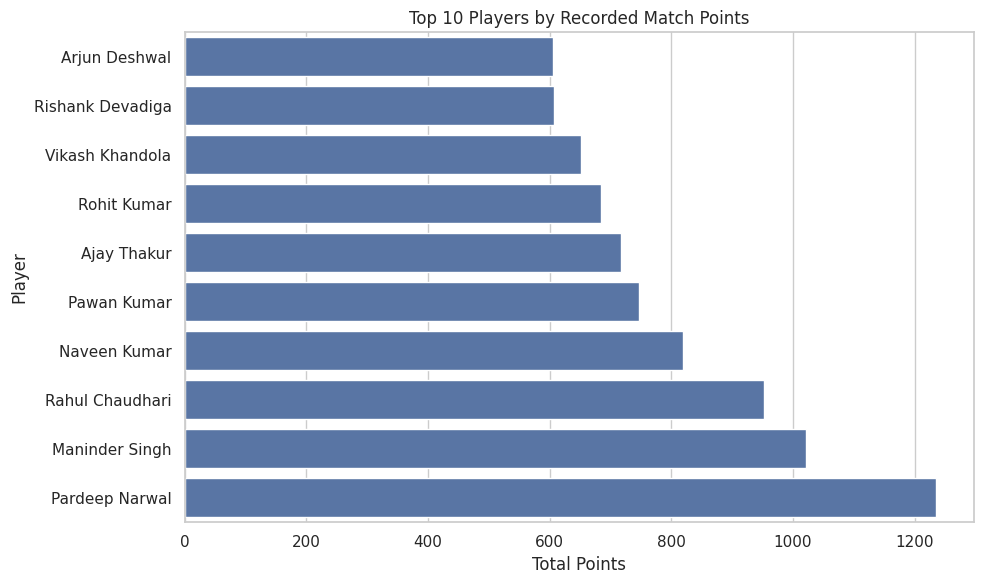

In [20]:
top_players = (
    players.groupby(["player_id", "player_name"])
    ["points"]
    .sum()
    .reset_index(name="total_points")
    .sort_values("total_points", ascending=False)
)

top10 = top_players.head(10).sort_values("total_points")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top10,
    x="total_points",
    y="player_name"
)

plt.title("Top 10 Players by Recorded Match Points")
plt.xlabel("Total Points")
plt.ylabel("Player")
plt.tight_layout()
plt.show()

**Investigate raiding versus defending**

In [21]:
print(teams.columns.tolist())
print(teams["season"].value_counts(dropna=False))

['season', 'team_id', 'team_name', 'matches_played', 'team-average-raid-points_rank', 'team-avg-points-scored_rank', 'team-all-outs-conceded_rank', 'team-successful-tackle-percent_rank', 'team-super-raid_rank', 'team-raid_rank', 'team-successful-raid-percent_rank', 'team-dod-raid-points_rank', 'team-super-tackles_rank', 'team-raid-points_rank', 'team-successful-raids_rank', 'team-total-points-conceded_rank', 'team-tackle-points_rank', 'team-total-points_rank', 'team-successful-tackles-per-match_rank', 'team-all-outs-inflicted_rank', 'team-average-tackle-points_rank', 'team-successful-tackles_rank', 'team-all-outs-conceded_value', 'team-successful-tackle-percent_value', 'team-super-raid_value', 'team-raid_value', 'team-successful-raid-percent_value', 'team-dod-raid-points_value', 'team-super-tackles_value', 'Total_touch_points_value', 'Total_bonus_points_value', 'team-raid-points_value', 'team-successful-raids_value', 'team-total-points-conceded_value', 'team-tackle-points_value', 'team

**Prepare the team-season data:**

In [22]:
team_stats = teams.copy()

team_stats["season"] = pd.to_numeric(
    team_stats["season"], errors="coerce"
)

team_stats = team_stats.dropna(subset=["season"]).copy()
team_stats["season"] = team_stats["season"].astype(int)

team_stats = team_stats[
    team_stats["season"].between(1, 10)
].copy()

team_stats["team_name"] = (
    team_stats["team_name"].map(clean_team_name)
)

metric_columns = [
    "team-tackle-points_per-match",
    "team-successful-tackle-percent_value",
    "team-raid-points_per-match",
    "team-successful-raid-percent_value",
    "team-total-points-conceded_per-match"
]

available_metrics = [
    c for c in metric_columns if c in team_stats.columns
]

display(team_stats[
    ["season", "team_name"] + available_metrics
].head())

,season,team_name,team-tackle-points_per-match,team-successful-tackle-percent_value,team-raid-points_per-match,team-successful-raid-percent_value,team-total-points-conceded_per-match
0,1,Bengaluru Bulls,10.188,NaN,18.188,NaN,29.938
1,1,Dabang Delhi K.C.,9.571,NaN,20.357,NaN,33.643
2,1,Jaipur Pink Panthers,10.625,NaN,21.500,NaN,28.625
3,1,Bengal Warriors,8.714,NaN,20.214,NaN,36.786
4,1,U Mumba,9.813,NaN,21.688,NaN,31.188


In [23]:
analysis = standings.merge(
    team_stats,
    left_on = ["season","team"],
    right_on=["season","team_name"],
    how = "left",
    validate = "many_to_one"
)
print("Standings rows:", len(standings))
print("Rows with matched team statistics:",
      analysis["team_name"].notna().sum())

Standings rows: 104
Rows with matched team statistics: 104


**Calculate correlations**

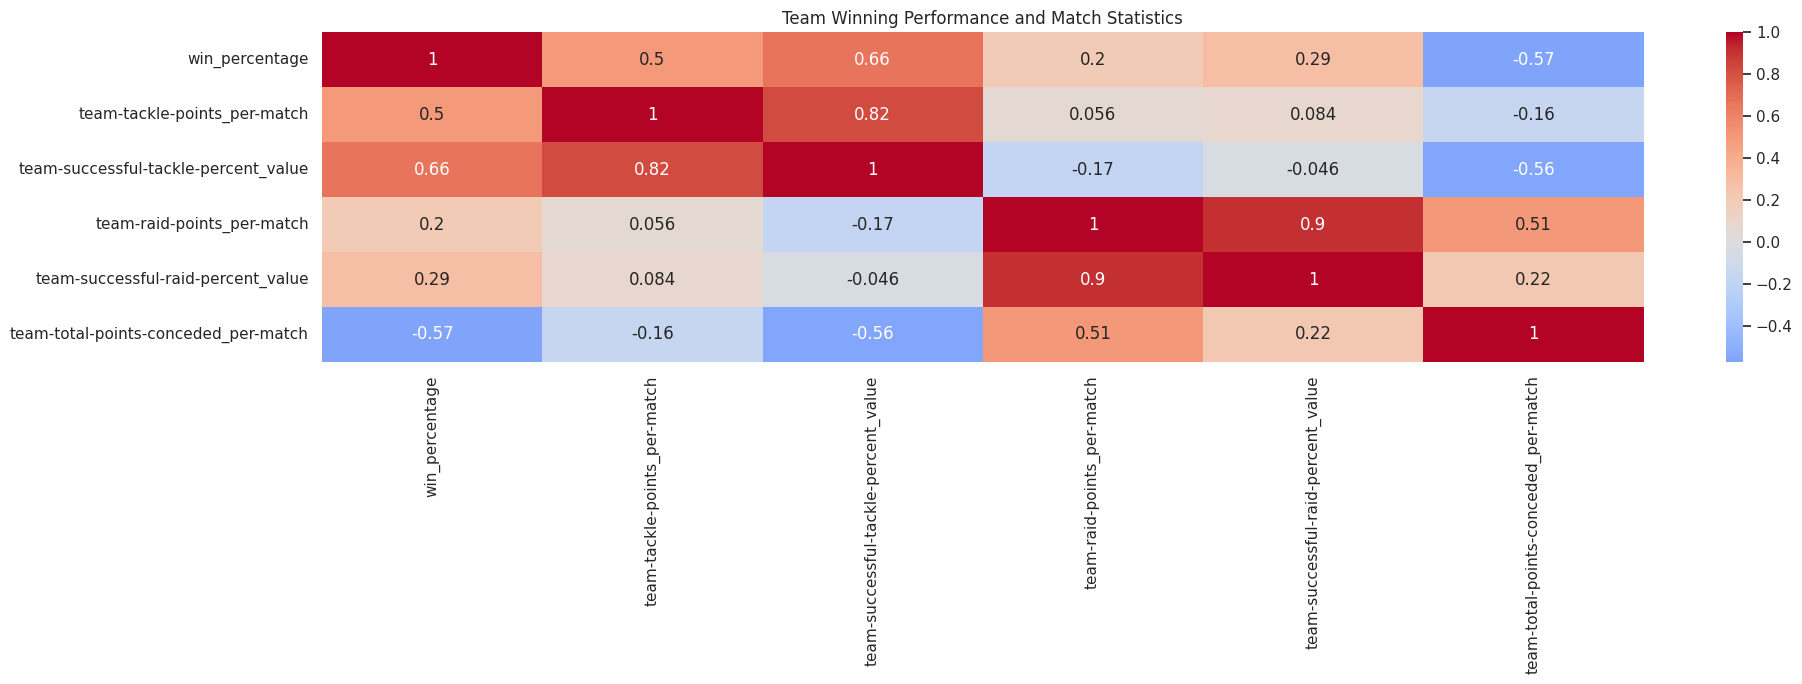

,win_percentage,team-tackle-points_per-match,team-successful-tackle-percent_value,team-raid-points_per-match,team-successful-raid-percent_value,team-total-points-conceded_per-match
win_percentage,1.000,0.497,0.665,0.199,0.294,-0.570
team-tackle-points_per-match,0.497,1.000,0.819,0.056,0.084,-0.156
team-successful-tackle-percent_value,0.665,0.819,1.000,-0.175,-0.046,-0.558
team-raid-points_per-match,0.199,0.056,-0.175,1.000,0.902,0.509
team-successful-raid-percent_value,0.294,0.084,-0.046,0.902,1.000,0.221
team-total-points-conceded_per-match,-0.570,-0.156,-0.558,0.509,0.221,1.000


In [24]:
correlation_data = analysis[
    ["win_percentage"]+ available_metrics
].copy()
correlation = correlation_data.corr(numeric_only=True)
plt.figure(figsize=(20,7))
sns.heatmap(
    correlation,
    annot = True,
    cmap="coolwarm",
    center=0
)
plt.title("Team Winning Performance and Match Statistics")
plt.tight_layout()
plt.show()

display(correlation.round(3))

**Perform statistical hypothesis tests**

In [25]:
import pandas as pd
from scipy import stats
from pathlib import Path

# Dynamically locate the dataset file to ensure robustness
target_file = "pkl_matches_s1_s10.csv"
matched_files = list(Path("/content").rglob(target_file))

if not matched_files:
    raise FileNotFoundError(f"Could not find {target_file} in /content. Please run the unzip/extraction cells first.")

file_path = matched_files[0]
print(f"Loading data from: {file_path}")

# Load and clean the data
matches = pd.read_csv(file_path)
for col in ["score_1", "score_2", "season"]:
    matches[col] = pd.to_numeric(matches[col], errors="coerce")
matches["total_points"] = matches["score_1"] + matches["score_2"]

# Separate into early and late seasons
early = matches.loc[
    matches["season"].between(1, 4), "total_points"
].dropna()

late = matches.loc[
    matches["season"].between(5, 10), "total_points"
].dropna()

# Perform Welch's t-test
t_stat, p_value = stats.ttest_ind(
    early, late, equal_var=False
)

print("Early seasons mean:", round(early.mean(), 2))
print("Later seasons mean:", round(late.mean(), 2))
print("Welch t-statistic:", round(t_stat, 3))
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject H0: the means differ significantly.")
else:
    print("Fail to reject H0: insufficient evidence of a difference.")

Loading data from: /content/pkl_project/Pro-Kabaddi-League-Analysis-main/data/pkl_matches_s1_s10.csv
Early seasons mean: 61.93
Later seasons mean: 68.39
Welch t-statistic: -8.567
p-value: 1.9508824281759486e-16
Reject H0: the means differ significantly.


In [29]:
import numpy as np
import pandas as pd
from scipy import stats

# Ensure calculated_winner exists on the matches DataFrame
if "calculated_winner" not in matches.columns:
    for col in ["score_1", "score_2", "season"]:
        matches[col] = pd.to_numeric(matches[col], errors="coerce")

    matches["calculated_winner"] = np.select(
        [
            matches["score_1"] > matches["score_2"],
            matches["score_2"] > matches["score_1"]
        ],
        [
            matches["team_1"],
            matches["team_2"]
        ],
        default="Tie"
    )

# Compute contingency table
contingency = pd.crosstab(
    matches["season"],
    matches["calculated_winner"].eq("Tie")
)

chi2, p_value, dof, expected = stats.chi2_contingency(
    contingency
)

print("Chi-square statistic:", round(chi2, 3))
print("Degrees of freedom:", dof)
print("p-value:", p_value)

if p_value < 0.05:
    print("Evidence of a difference in tie rates across seasons.")
else:
    print("Insufficient evidence of a difference in tie rates.")

Chi-square statistic: 3.195
Degrees of freedom: 9
p-value: 0.9560815838871979
Insufficient evidence of a difference in tie rates.


In [34]:
def correlation_test(data, x_col, y_col):
    clean = data[[x_col, y_col]].dropna()
    print(f"\n{x_col} vs {y_col}")
    print("Sample size:", len(clean))

    if len(clean) < 3:
        print("Not enough observations for a correlation test.")
        return

    r, p = stats.pearsonr(
        clean[x_col], clean[y_col]
    )

    print("Pearson correlation:", round(r, 3))
    print("p-value:", round(p, 5))

    if p < 0.05:
        print("Evidence of a linear association.")
    else:
        print("Insufficient evidence of a linear association.")

for metric in available_metrics:
    correlation_test(
        analysis, "win_percentage", metric
    )


win_percentage vs team-tackle-points_per-match
Sample size: 104
Pearson correlation: 0.497
p-value: 0.0
Evidence of a linear association.

win_percentage vs team-successful-tackle-percent_value
Sample size: 48
Pearson correlation: 0.665
p-value: 0.0
Evidence of a linear association.

win_percentage vs team-raid-points_per-match
Sample size: 104
Pearson correlation: 0.199
p-value: 0.04338
Evidence of a linear association.

win_percentage vs team-successful-raid-percent_value
Sample size: 48
Pearson correlation: 0.294
p-value: 0.0429
Evidence of a linear association.

win_percentage vs team-total-points-conceded_per-match
Sample size: 104
Pearson correlation: -0.57
p-value: 0.0
Evidence of a linear association.


In [35]:
import pandas as pd
import numpy as np
from scipy import stats

# Inspect the venues available in the dataset.
print(
    matches["venue"]
    .value_counts(dropna=False)
    .to_string()
)

venue
Sheraton Grand, Whitefield, Bengaluru                       137
Gachibowli Indoor Stadium, Hyderabad                         71
Shree Kanteerava Indoor Stadium, Bengaluru                   52
DOME,NSCI,SVP STADIUM,MUMBAI                                 43
Shree Shivchhatrapati Sports Complex,Balewadi, Pune          42
Netaji Indoor Stadium                                        39
Thyagaraj Indoor Stadium                                     39
Sawai Mansingh Stadium                                       39
Thyagaraj Indoor Stadium, Delhi                              33
Netaji Indoor Stadium, Kolkata                               33
Gachibowli Indoor Stadium                                    29
Patliputra Indoor Stadium                                    28
Kanteerava Indoor Stadium                                    28
The Arena by TransStadia, Ahmedabad                          27
DOME,NSCI,SVP STADIUM,MUMBAI, Mumbai                         25
Kanteerava Indoor Stadium, Bengalu

In [36]:
def normalize_venue(venue):
    if pd.isna(venue):
        return None

    v = str(venue).lower()

    # Match more specific or unusual venue names first.
    if "sheraton whitefield" in v or "bengaluru" in v:
        return "Bengaluru"
    if "nsci" in v or "dome" in v:
        return "Mumbai"
    if "thyagaraj" in v:
        return "Delhi"
    if "netaji indoor" in v:
        return "Kolkata"

    # Add other venue mappings only after verifying them.
    return None

matches["venue_city"] = matches["venue"].apply(normalize_venue)

display(
    matches[["venue", "venue_city"]]
    .drop_duplicates()
    .sort_values("venue")
)

,venue,venue_city
273,Babu Banarasi Das Indoor Stadium,None
949,"Badminton Hall in Balewadi sports complex,Pune...",None
982,"DOME by NSCI, Mumbai",Mumbai
0,"DOME,NSCI,SVP STADIUM,MUMBAI",Mumbai
431,"DOME,NSCI,SVP STADIUM,MUMBAI, Mumbai",Mumbai
927,"EKA Arena by TransStadia, Ahmedabad",None
1004,"GMC Balayogi Sports Complex, Gachibowli, Hyder...",None
88,Gachibowli Indoor Stadium,None
477,"Gachibowli Indoor Stadium, Hyderabad",None
378,"JAWAHARLAL NEHRU INDOOR STADIUM, Chennai",None


In [37]:
# Fill this table using verified PKL schedules or official records.
# Each row must describe a team's home city for that season.

home_records = [
    # Example structure — replace/add verified records:
    # {"season": 1, "team": "Jaipur Pink Panthers",
    #  "home_city": "Jaipur"},
    # {"season": 1, "team": "U Mumba",
    #  "home_city": "Mumbai"},
]

home_cities = pd.DataFrame(
    home_records,
    columns=["season", "team", "home_city"]
)

if not home_cities.empty:
    home_cities["team"] = home_cities["team"].map(clean_team_name)
    home_cities["season"] = pd.to_numeric(
        home_cities["season"], errors="raise"
    ).astype(int)

    assert not home_cities.duplicated(
        ["season", "team"]
    ).any(), "Duplicate team-season home-city assignments!"

display(home_cities)

,season,team,home_city


In [38]:
if home_cities.empty:
    print(
        "Home-city mapping is empty. Verify team home cities "
        "before testing home advantage."
    )
else:
    home_lookup = home_cities.set_index(
        ["season", "team"]
    )["home_city"]

    matches["team_1_home_city"] = [
        home_lookup.get((int(s), t), None)
        for s, t in zip(matches["season"], matches["team_1"])
    ]

    matches["team_2_home_city"] = [
        home_lookup.get((int(s), t), None)
        for s, t in zip(matches["season"], matches["team_2"])
    ]

    matches["home_team"] = None

    home_1 = (
        matches["venue_city"].notna()
        & matches["team_1_home_city"].notna()
        & matches["team_2_home_city"].notna()
        & (matches["venue_city"] == matches["team_1_home_city"])
        & (matches["venue_city"] != matches["team_2_home_city"])
    )

    home_2 = (
        matches["venue_city"].notna()
        & matches["team_1_home_city"].notna()
        & matches["team_2_home_city"].notna()
        & (matches["venue_city"] == matches["team_2_home_city"])
        & (matches["venue_city"] != matches["team_1_home_city"])
    )

    matches.loc[home_1, "home_team"] = matches.loc[home_1, "team_1"]
    matches.loc[home_2, "home_team"] = matches.loc[home_2, "team_2"]

    display(
        matches[
            ["season", "venue", "venue_city",
             "team_1", "team_2", "home_team"]
        ].head(15)
    )

Home-city mapping is empty. Verify team home cities before testing home advantage.


In [39]:
if home_cities.empty:
    print("Cannot test home advantage without verified home-city data.")
else:
    home_matches = matches[
        matches["home_team"].notna()
        & (matches["calculated_winner"] != "Tie")
    ].copy()

    home_matches["home_win"] = (
        home_matches["calculated_winner"]
        == home_matches["home_team"]
    )

    n = len(home_matches)
    home_wins = int(home_matches["home_win"].sum())

    if n == 0:
        print("No classifiable decisive home matches were found.")
    else:
        home_win_rate = home_wins / n

        test = stats.binomtest(
            home_wins,
            n,
            p=0.5,
            alternative="greater"
        )

        print("Decisive home matches:", n)
        print("Home wins:", home_wins)
        print(f"Home win rate: {home_win_rate:.1%}")
        print(f"One-sided binomial p-value: {test.pvalue:.4f}")

        if test.pvalue < 0.05:
            print(
                "Evidence that the home win rate exceeds 50%, "
                "for this classified sample."
            )
        else:
            print(
                "Insufficient evidence that the home win rate "
                "exceeds 50%, for this classified sample."
            )

Cannot test home advantage without verified home-city data.


**Key findings and recommendations**

In [40]:
# 1. Scoring trend: Seasons 1–4 vs Seasons 5–10
early_scores = matches.loc[
    matches["season"].between(1, 4), "total_points"
].dropna()

late_scores = matches.loc[
    matches["season"].between(5, 10), "total_points"
].dropna()

score_test = stats.ttest_ind(
    early_scores, late_scores, equal_var=False
)

print("=" * 55)
print("1. MATCH SCORING")
print("=" * 55)
print(f"Seasons 1–4 average: {early_scores.mean():.2f}")
print(f"Seasons 5–10 average: {late_scores.mean():.2f}")
print(f"Welch t-test p-value: {score_test.pvalue:.6g}")

if score_test.pvalue < 0.05:
    direction = (
        "increased" if late_scores.mean() > early_scores.mean()
        else "decreased"
    )
    print(f"Conclusion: Average scoring {direction} significantly.")
else:
    print("Conclusion: No statistically significant difference detected.")


# 2. Team rankings
print("\n" + "=" * 55)
print("2. TEAM PERFORMANCE")
print("=" * 55)

display(all_time.head(5).round(2))


# 3. Player rankings
print("\n" + "=" * 55)
print("3. TOP PLAYERS")
print("=" * 55)

display(top_players.head(5))


# 4. Tie-rate hypothesis test
print("\n" + "=" * 55)
print("4. TIE RATE BY SEASON")
print("=" * 55)

tie_table = pd.crosstab(
    matches["season"],
    matches["calculated_winner"].eq("Tie")
)

tie_chi2, tie_p, tie_dof, tie_expected = (
    stats.chi2_contingency(tie_table)
)

print(f"Chi-square statistic: {tie_chi2:.3f}")
print(f"Degrees of freedom: {tie_dof}")
print(f"p-value: {tie_p:.5f}")

if tie_p < 0.05:
    print("Conclusion: Evidence of differing tie rates across seasons.")
else:
    print("Conclusion: Insufficient evidence of differing tie rates.")


# 5. Defensive-performance correlation
print("\n" + "=" * 55)
print("5. DEFENCE AND WINNING")
print("=" * 55)

tackle_metrics = [
    "team-tackle-points_per-match",
    "team-successful-tackle-percent_value"
]

for metric in tackle_metrics:
    if metric not in analysis.columns:
        continue

    sample = analysis[
        ["win_percentage", metric]
    ].dropna()

    if len(sample) < 3:
        print(f"{metric}: insufficient observations")
        continue

    r, p = stats.pearsonr(
        sample["win_percentage"], sample[metric]
    )

    print(f"\nMetric: {metric}")
    print(f"Sample size: {len(sample)}")
    print(f"Pearson r: {r:.3f}")
    print(f"p-value: {p:.5f}")

1. MATCH SCORING
Seasons 1–4 average: 61.93
Seasons 5–10 average: 68.39
Welch t-test p-value: 1.95088e-16
Conclusion: Average scoring increased significantly.

2. TEAM PERFORMANCE


,team,played,wins,losses,ties,win_percentage
10,U Mumba,197,106,78,13,53.81
3,Gujarat Giants,139,73,53,13,52.52
6,Patna Pirates,204,107,77,20,52.45
5,Jaipur Pink Panthers,195,97,81,17,49.74
4,Haryana Steelers,137,67,57,13,48.91



3. TOP PLAYERS


,player_id,player_name,total_points
147,197,Pardeep Narwal,1236
93,143,Maninder Singh,1021
60,81,Rahul Chaudhari,953
410,2296,Naveen Kumar,819
252,318,Pawan Kumar,747



4. TIE RATE BY SEASON
Chi-square statistic: 3.195
Degrees of freedom: 9
p-value: 0.95608
Conclusion: Insufficient evidence of differing tie rates.

5. DEFENCE AND WINNING

Metric: team-tackle-points_per-match
Sample size: 104
Pearson r: 0.497
p-value: 0.00000

Metric: team-successful-tackle-percent_value
Sample size: 48
Pearson r: 0.665
p-value: 0.00000
